# Machine Learning Lab: Decision Tree and Random Forest Classification

## Bank Marketing Dataset

**Objectives**

1. Implement a baseline Decision Tree and Random Forest classifier.
2. Study the effect of `max_depth` on Random Forest performance.
3. Study the effect of `n_estimators` on Random Forest performance.
4. Compare Accuracy, Precision, and Recall using tables and graphs.

**Dataset source:** Moro, S., Rita, P., & Cortez, P. (2014), *Bank Marketing*, UCI Machine Learning Repository, DOI: 10.24432/C5K306.

Source: https://archive.ics.uci.edu/dataset/222/bank

## 1. Import Libraries

The libraries below are used for data handling, preprocessing, model training, evaluation, and visualization.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
plt.style.use("default")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.25})
RANDOM_STATE = 42

## 2. Load the Dataset

The dataset contains client information and a target variable indicating whether the client subscribed to a term deposit.

In [2]:
from pathlib import Path

paths = list(Path("/kaggle/input").rglob("bank-full.csv")) if Path("/kaggle/input").exists() else []
if not paths:
    paths = list(Path(".").rglob("bank-full.csv"))

if not paths:
    raise FileNotFoundError("bank-full.csv was not found. Add the Bank Marketing dataset to the Kaggle notebook input.")

df = pd.read_csv(paths[0], sep=";")
print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Dataset loaded successfully.
Rows: 45211
Columns: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Initial Data Inspection

The first rows, data types, target distribution, missing values, and duplicate rows are checked before preprocessing.

In [3]:
print("Data types:")
display(df.dtypes)

print("Target distribution:")
display(df["y"].value_counts())

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Data types:


age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Target distribution:


y
no     39922
yes     5289
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0


## 4. Data Preprocessing

The target `y` is converted from `yes/no` to `1/0`. Numerical features are passed through directly. Categorical features are converted using one-hot encoding. A stratified 80:20 train-test split is used so that the class proportions are maintained.

In [4]:
X = df.drop(columns=["y"])
y = df["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Numerical features: 7
Categorical features: 9
Training samples: 36168
Testing samples: 9043


## 5. Theory

A Decision Tree recursively divides the data into smaller groups. The default Gini impurity used here is

$$Gini = 1 - \sum_{k=1}^{K} p_k^2$$

where $p_k$ is the proportion of class $k$ in a node.

A Random Forest combines multiple decision trees. For classification, the final class is obtained by majority voting:

$$\hat{y} = mode\{T_1(x), T_2(x), \ldots, T_B(x)\}$$

where $B$ is the number of trees. `max_depth` controls tree complexity, while `n_estimators` controls the number of trees.

## 6. Evaluation Measures

For binary classification, the main measures are:

$$Accuracy = \frac{TP+TN}{TP+TN+FP+FN}$$

$$Precision = \frac{TP}{TP+FP}$$

$$Recall = \frac{TP}{TP+FN}$$

Weighted Precision and weighted Recall are used because the two target classes are not equally frequent.

## 7. Baseline Comparison

A single Decision Tree is compared with a Random Forest containing 100 trees. The same preprocessing and test set are used for both models.

In [5]:
def evaluate(model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    return [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0)
    ], pred

dt = Pipeline([("prep", preprocessor), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])
rf = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])

dt_scores, dt_pred = evaluate(dt)
rf_scores, rf_pred = evaluate(rf)

baseline = pd.DataFrame([dt_scores, rf_scores], columns=["Accuracy", "Precision", "Recall"], index=["Decision Tree", "Random Forest"])
display(baseline.round(4))

,Accuracy,Precision,Recall
Decision Tree,0.8746,0.8758,0.8746
Random Forest,0.9043,0.8919,0.9043


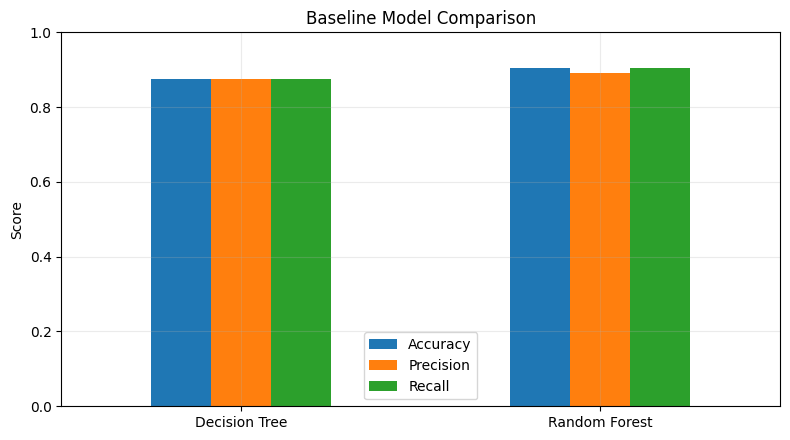

In [6]:
baseline.plot(kind="bar", ylim=(0, 1), figsize=(8, 4.5))
plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Experiment 1: Effect of `max_depth`

The number of trees is fixed at 100 while the maximum tree depth is varied.

$$max\_depth \in \{2, 5, 10, 15\}$$

In [7]:
depth_values = [2, 5, 10, 15]
depth_results = []

for depth in depth_values:
    model = Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=RANDOM_STATE, n_jobs=-1))
    ])
    scores, _ = evaluate(model)
    depth_results.append([depth, *scores])

depth_results = pd.DataFrame(depth_results, columns=["max_depth", "Accuracy", "Precision", "Recall"])
display(depth_results.round(4))

,max_depth,Accuracy,Precision,Recall
0,2,0.8830,0.7797,0.8830
1,5,0.8943,0.8830,0.8943
2,10,0.8977,0.8842,0.8977
3,15,0.9053,0.8921,0.9053


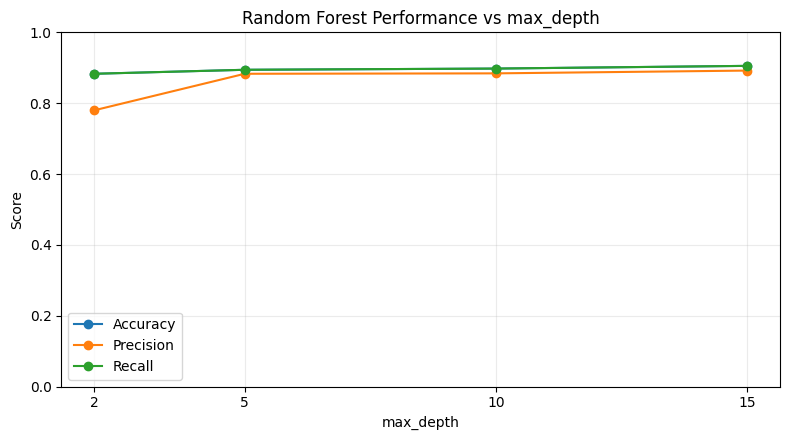

In [8]:
plt.figure(figsize=(8, 4.5))
for metric in ["Accuracy", "Precision", "Recall"]:
    plt.plot(depth_results["max_depth"], depth_results[metric], marker="o", label=metric)
plt.title("Random Forest Performance vs max_depth")
plt.xlabel("max_depth")
plt.ylabel("Score")
plt.xticks(depth_values)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Observation

The graph shows the change in the three evaluation measures as tree depth increases. A small depth restricts model complexity, while a larger depth permits more detailed splits. The best value is determined from the measured results.

## 9. Experiment 2: Effect of `n_estimators`

The maximum tree depth is fixed at 10 while the number of trees is varied.

$$n\_estimators \in \{10, 50, 100, 200\}$$

In [9]:
estimator_values = [10, 50, 100, 200]
estimator_results = []

for n in estimator_values:
    model = Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=n, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1))
    ])
    scores, _ = evaluate(model)
    estimator_results.append([n, *scores])

estimator_results = pd.DataFrame(estimator_results, columns=["n_estimators", "Accuracy", "Precision", "Recall"])
display(estimator_results.round(4))

,n_estimators,Accuracy,Precision,Recall
0,10,0.8977,0.8815,0.8977
1,50,0.8979,0.8828,0.8979
2,100,0.8977,0.8842,0.8977
3,200,0.8974,0.8834,0.8974


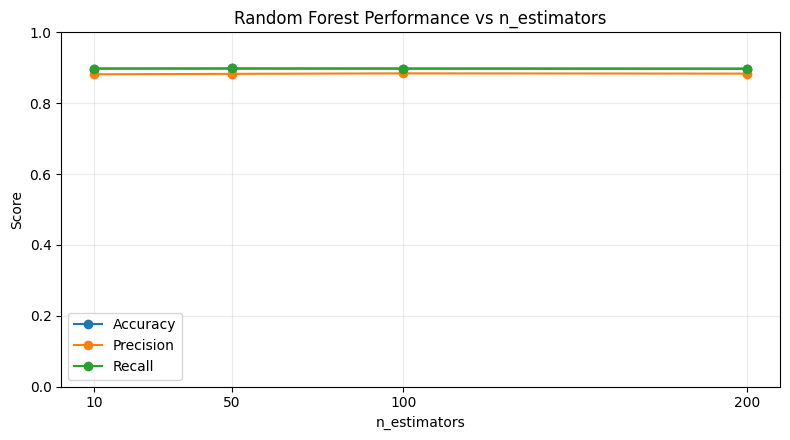

In [10]:
plt.figure(figsize=(8, 4.5))
for metric in ["Accuracy", "Precision", "Recall"]:
    plt.plot(estimator_results["n_estimators"], estimator_results[metric], marker="o", label=metric)
plt.title("Random Forest Performance vs n_estimators")
plt.xlabel("n_estimators")
plt.ylabel("Score")
plt.xticks(estimator_values)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Observation

The graph shows how the performance changes as more trees are added. Increasing the ensemble size generally improves stability, while the improvement can become small after a sufficient number of trees.

## 10. Confusion Matrix

The confusion matrix gives the number of correct and incorrect predictions for the baseline Random Forest.

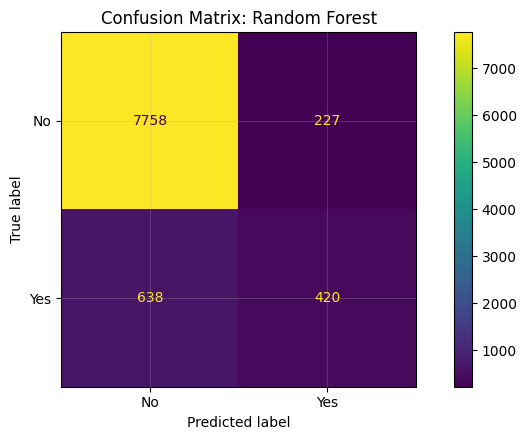

In [11]:
cm = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot()
plt.title("Confusion Matrix: Random Forest")
plt.tight_layout()
plt.show()

## 11. Key Findings

- The dataset contains both numerical and categorical variables.
- Categorical variables require encoding before model training.
- The baseline compares a single Decision Tree with a Random Forest.
- `max_depth` changes the complexity of the trees in the forest.
- `n_estimators` changes the size of the ensemble.
- Accuracy, Precision, and Recall provide different views of classification performance.
- The experimental results provide an empirical basis for selecting model parameters.

## 12. Learning Outcomes

After completing this experiment, a student should be able to:

1. Explain the basic working of a Decision Tree classifier.
2. Explain the principle of Random Forest classification.
3. Preprocess numerical and categorical features.
4. Apply one-hot encoding to categorical variables.
5. Calculate and interpret Accuracy, Precision, and Recall.
6. Explain the effect of `max_depth` on tree complexity.
7. Explain the effect of `n_estimators` on ensemble size.
8. Compare model performance using tables and graphs.
9. Interpret experimental results.

## 13. Conclusion

The experiment demonstrates Decision Tree and Random Forest classification on the Bank Marketing dataset. The baseline establishes a simple comparison between a single tree and an ensemble. The two experiments show how tree depth and ensemble size affect the measured classification performance. The results illustrate the importance of preprocessing, evaluation measures, and parameter selection in a machine learning classification task.

### References

1. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. DOI: 10.24432/C5K306.
2. UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/222/bank
3. Scikit-learn documentation: https://scikit-learn.org/stable/modules/tree.html
4. Scikit-learn documentation: https://scikit-learn.org/stable/modules/ensemble.html#random-forests